# Lab I: Multi-View VAE — MNIST and SVHN




## Model

Both images share a latent variable $z$:
$$p(z)=\mathcal N(0,I),\qquad p(x_M,x_S\mid z)=p(x_M\mid z)p(x_S\mid z).$$

Each decoder predicts the mean of a Gaussian with fixed observation variance. We train by minimizing the negative ELBO:
$$-\mathbb E_q[\log p(x_M\mid z)+\log p(x_S\mid z)]+KL(q\Vert p).$$

We sample with $z=\mu+\sqrt{\mathrm{var}}\,\epsilon$, where $\epsilon\sim\mathcal N(0,I)$. Throughout the code, `var` means variance.


In [3]:
%pip -q install scipy scikit-learn matplotlib tqdm


In [4]:
# Use False for the full experiment.
import os, json, random, math, inspect
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
QUICK_RUN = False
EPOCHS = 20
LATENT_DIM, BATCH_SIZE, LR = 32, 64, 1e-3
WARMUP_EPOCHS = 5
OUT = Path('mvae_results'); OUT.mkdir(exist_ok=True)
print('Device:', device, '| torch:', torch.__version__, '| torchvision:', torchvision.__version__)
if device.type == 'cpu': print('Full training may be slow without a GPU.')


Device: cuda | torch: 2.11.0+cu130 | torchvision: 0.26.0+cu130


## 1. Load and pair the data

We split each training dataset into 90% training and 10% validation before pairing. The official test sets stay separate.

Within each split, we pair images with the same label without reusing images. The trainign pairs change in each epoch and the validation and test stay fixed

Images are resized to 64×64 and scaled to [-1, 1]
MNIST has one channel and SVHN has three.
 Torchvision maps the SVHN label 10 to digit 0.


In [5]:
# Keep workers disabled so training pairs can change each epoch.
tfm_m = transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(),
                            transforms.Normalize((0.5,), (0.5,))])
tfm_s = transforms.Compose([transforms.Resize((64,64)), transforms.ToTensor(),
                            transforms.Normalize((0.5,)*3, (0.5,)*3)])
mn_train = datasets.MNIST('data/mnist', train=True, download=True, transform=tfm_m)
mn_test = datasets.MNIST('data/mnist', train=False, download=True, transform=tfm_m)
sv_train = datasets.SVHN('data/svhn', split='train', download=True, transform=tfm_s)
sv_test = datasets.SVHN('data/svhn', split='test', download=True, transform=tfm_s)

def labels_of(ds):
    return np.asarray(ds.targets if hasattr(ds, 'targets') else ds.labels)

def split_indices(ds):
    ids = np.arange(len(ds))
    return train_test_split(ids, test_size=.1, random_state=SEED, stratify=labels_of(ds))

mi_tr, mi_va = split_indices(mn_train)
si_tr, si_va = split_indices(sv_train)
assert not set(mi_tr) & set(mi_va)
assert not set(si_tr) & set(si_va)

class PairedDigits(Dataset):
    def __init__(self, mnist, svhn, mn_ids, sv_ids, seed, max_per_class=None):
        self.mnist, self.svhn = mnist, svhn
        self.mn_ids, self.sv_ids = np.asarray(mn_ids), np.asarray(sv_ids)
        self.ml, self.sl = labels_of(mnist), labels_of(svhn)
        self.seed, self.cap = seed, max_per_class
        self.repair(0)

    def repair(self, epoch):
        rng = np.random.default_rng(self.seed + epoch)
        pairs = []
        for digit in range(10):
            a = rng.permutation(self.mn_ids[self.ml[self.mn_ids] == digit])
            b = rng.permutation(self.sv_ids[self.sl[self.sv_ids] == digit])
            n = min(len(a), len(b))
            if self.cap is not None: n = min(n, self.cap)
            pairs.extend(zip(a[:n], b[:n]))
        self.pairs = np.asarray(pairs, dtype=np.int64)
        rng.shuffle(self.pairs)
        assert len(self.pairs) > 0
        assert np.all(self.ml[self.pairs[:, 0]] == self.sl[self.pairs[:, 1]])
        assert len(np.unique(self.pairs[:, 0])) == len(self.pairs)
        assert len(np.unique(self.pairs[:, 1])) == len(self.pairs)

    def __len__(self): return len(self.pairs)
    def __getitem__(self, i):
        a, b = self.pairs[i]
        xm, ym = self.mnist[int(a)]
        xs, ys = self.svhn[int(b)]
        assert int(ym) == int(ys)
        return xm, xs, int(ym)

train_ds = PairedDigits(mn_train, sv_train, mi_tr, si_tr, SEED, 500 if QUICK_RUN else None)
val_ds = PairedDigits(mn_train, sv_train, mi_va, si_va, SEED+100, 100 if QUICK_RUN else None)
test_ds = PairedDigits(mn_test, sv_test, np.arange(len(mn_test)), np.arange(len(sv_test)),
                       SEED+200, 100 if QUICK_RUN else None)

def loader(ds, shuffle=False):
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      pin_memory=device.type == 'cuda')
train_loader, val_loader, test_loader = loader(train_ds, True), loader(val_ds), loader(test_ds)
for name, ds in [('train', train_ds), ('val', val_ds), ('test', test_ds)]:
    print(name, len(ds), 'pairs; class counts:', np.bincount(ds.ml[ds.pairs[:,0]], minlength=10))


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.22MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 492kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.21MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.92MB/s]
100%|██████████| 182M/182M [00:46<00:00, 3.91MB/s]
100%|██████████| 64.3M/64.3M [00:02<00:00, 29.7MB/s]


train 50462 pairs; class counts: [4453 6068 5362 5518 5258 4879 5154 5036 4541 4193]
val 5606 pairs; class counts: [495 674 596 613 584 542 573 559 504 466]
test 10000 pairs; class counts: [ 980 1135 1032 1010  982  892  958 1028  974 1009]


Labels of the first pairs: [7, 7, 1, 1, 0, 8, 2, 4, 5, 9]


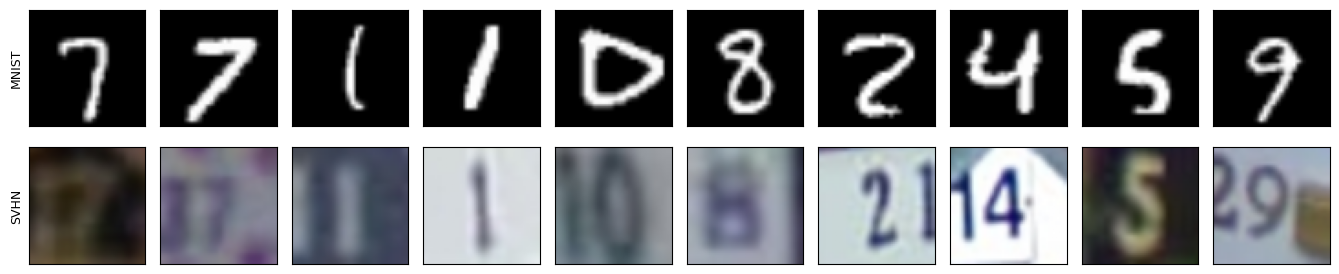

In [6]:
def show_rows(rows, titles, filename, n=10):
    fig, axes = plt.subplots(len(rows), n, figsize=(1.35*n, 1.55*len(rows)), squeeze=False)
    for r, (batch, title) in enumerate(zip(rows, titles)):
        batch = batch.detach().cpu()
        for c in range(n):
            img = (batch[c]/2 + 0.5).clamp(0, 1)
            axes[r,c].imshow(img[0] if img.shape[0] == 1 else img.permute(1,2,0),
                             cmap='gray' if img.shape[0] == 1 else None, vmin=0, vmax=1)
            axes[r,c].set_xticks([]); axes[r,c].set_yticks([])
        axes[r,0].set_ylabel(title, fontsize=9)
    plt.tight_layout(); fig.savefig(OUT / filename, dpi=160, bbox_inches='tight'); plt.show()

xm, xs, y = next(iter(test_loader))
print('Labels of the first pairs:', y[:10].tolist())
assert xm.shape[1:] == (1,64,64) and xs.shape[1:] == (3,64,64)
show_rows([xm, xs], ['MNIST', 'SVHN'], '01_pairs.png')


## 2. Encoder

We have reused the convolutional layers from the class notebook, with one encoder per dataset. Each encoder returns a mean and a positive variance.



In [7]:
class encoder(nn.Module):

    def __init__(self,dimz,channels=3,var_x=0.1):

        super().__init__()

        self.dimz = dimz

        self.conv1 = nn.Conv2d(in_channels=channels, out_channels=32,
                               kernel_size=4, stride=2, padding=1)

        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=32,
                               kernel_size=4, stride=2, padding=1)

        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64,
                               kernel_size=4, stride=2, padding=1)

        self.conv4 = nn.Conv2d(in_channels=64, out_channels=64,
                               kernel_size=4, stride=2, padding=1)

        self.conv5 = nn.Conv2d(in_channels=64, out_channels=256,
                               kernel_size=4, stride=1, padding=0)

        self.linear = nn.Linear(256,dimz*2)

        self.softplus = nn.Softplus()

    def forward(self,x):

        z = self.relu(self.conv1(x))
        z = self.relu(self.conv2(z))
        z = self.relu(self.conv3(z))
        z = self.relu(self.conv4(z))
        z = self.relu(self.conv5(z))

        z = z.view(-1,256)
        z = self.linear(z)

        return z

    def encode_and_sample(self,x,flag_sample=True):

        z = self.forward(x)

        mu = z[:, :self.dimz]

        var = self.softplus(0.5 * z[:, self.dimz:]).clamp_min(1e-6)

        sample = None

        if(flag_sample==True):

            eps = torch.randn_like(var)

            sample = mu + eps*(var**0.5)

        return mu,var,sample


### Check the encoder

We use two latent dimensions here to check shapes and positive variances. These example encoders are not trained. The final model uses 32 dimensions.


In [8]:
demo_m, demo_s, demo_labels = next(iter(train_loader))
demo_m, demo_s = demo_m[:10].to(device), demo_s[:10].to(device)
my_enc_m = encoder(dimz=2, channels=1).to(device)
my_enc_s = encoder(dimz=2, channels=3).to(device)
with torch.no_grad():
    mu_m, var_m, sample_m = my_enc_m.encode_and_sample(demo_m)
    mu_s, var_s, sample_s = my_enc_s.encode_and_sample(demo_s)
for name,mu,var,sample in [('MNIST',mu_m,var_m,sample_m),('SVHN',mu_s,var_s,sample_s)]:
    assert mu.shape == (10,2) and var.shape == (10,2) and (var>0).all()
    print(name, '| mean:',mu[0].cpu().numpy(), '| variance:',var[0].cpu().numpy())
    print('Sample:',sample[0].cpu().numpy())


MNIST | mean: [0.02735401 0.05179359] | variance: [0.70046616 0.7034709 ]
Sample: [0.18973583 1.8646061 ]
SVHN | mean: [-0.04710427 -0.02220027] | variance: [0.690167   0.69252175]
Sample: [ 0.06848605 -0.11225587]


## 3. Decoder

We have reused the class decoder with one output channel for MNIST and three for SVHN. Its `Tanh` output matches the [-1, 1] input range.


In [9]:
class decoder(nn.Module):

    def __init__(self,dimz,channels=3,var_x=0.1):

        super().__init__()

        self.linear = nn.Linear(dimz,256)

        self.relu = nn.ReLU()

        self.tanh = nn.Tanh()

        self.tconv1 = nn.ConvTranspose2d(256, 64, kernel_size=4, stride=1,padding=0)

        self.tconv2 = nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2,padding=1)

        self.tconv3 = nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2,padding=1)

        self.tconv4 = nn.ConvTranspose2d(32, 32, kernel_size=4, stride=2,padding=1)

        self.tconv5 = nn.ConvTranspose2d(32, channels, kernel_size=4, stride=2,padding=1)

    def forward(self,z):

        x = self.relu(self.linear(z).view(-1,256,1,1))
        x = self.relu(self.tconv1(x))
        x = self.relu(self.tconv2(x))
        x = self.relu(self.tconv3(x))
        x = self.relu(self.tconv4(x))
        x = self.tanh(self.tconv5(x))
        return x

    def decode(self,z):

        return self.forward(z)


### Check the decoder

We decode the encoder means to check output shapes. The networks still have random weights, so these are not trained reconstructions.


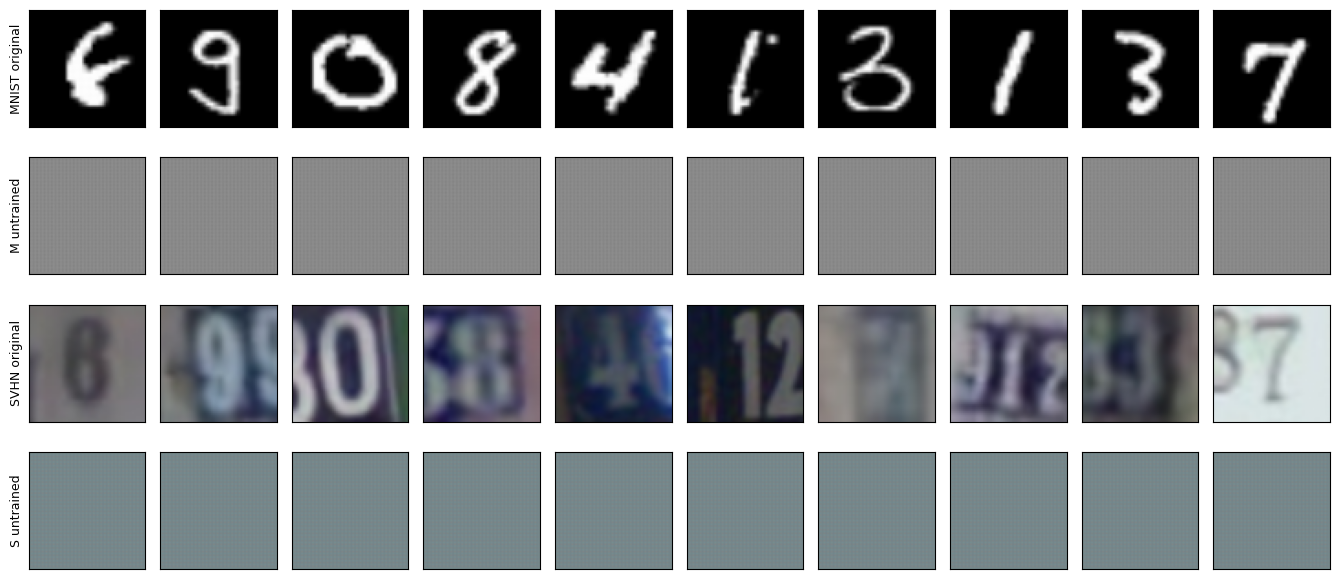

In [10]:
my_dec_m = decoder(dimz=2, channels=1).to(device)
my_dec_s = decoder(dimz=2, channels=3).to(device)
with torch.no_grad():
    x_mean_m = my_dec_m.decode(mu_m)
    x_mean_s = my_dec_s.decode(mu_s)
assert x_mean_m.shape == demo_m.shape and x_mean_s.shape == demo_s.shape
show_rows([demo_m,x_mean_m,demo_s,x_mean_s],
          ['MNIST original','M untrained','SVHN original','S untrained'],
          '00_untrained_reconstruction.png')


## 4. Gaussian log-likelihood

We reuse `eval_Gaussian_LL` from the class notebook for each view:
$$\log p(x\mid z)=-\frac12\left[D\log(2\pi)+D\log(\mathrm{var}_x)+\frac{\|x-\mu_x\|^2}{\mathrm{var}_x}\right].$$

Here, `var_x` is the fixed observation variance, separate from the latent variance.


In [11]:
def eval_Gaussian_LL(x,mu_x,var_x):

    D = x.shape[1] * x.shape[2] * x.shape[3]

    x = x.reshape(-1, D)

    mu_x = mu_x.reshape(-1, D)

    var_x = torch.ones_like(mu_x) * var_x

    cnt = D * np.log(2 * np.pi) + torch.sum(torch.log(var_x), dim=-1)

    logp_data = -0.5 * (cnt + torch.sum((x - mu_x) * var_x ** -1 * (x - mu_x), dim=-1))

    logp = torch.sum(logp_data)

    return logp,logp_data


### Check the likelihood

We evaluate the untrained reconstructions with observation variance 0.1. SVHN has three times as many pixel values, so its log-likelihood has a different scale.


MNIST log-likelihood, first image: -19673.95703125
SVHN log-likelihood, first image: -1353.5009765625


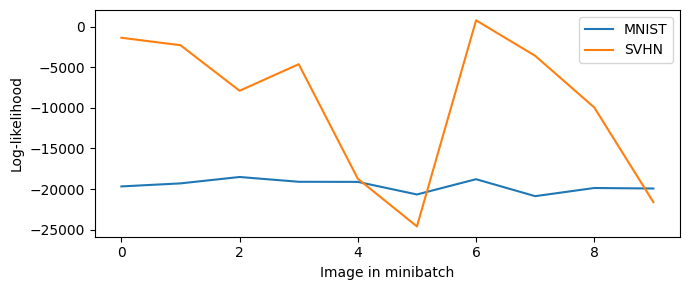

SVHN has three times as many pixel values; likelihood scales differ.


In [12]:
with torch.no_grad():
    logp_m, logp_data_m = eval_Gaussian_LL(demo_m,x_mean_m,0.1)
    logp_s, logp_data_s = eval_Gaussian_LL(demo_s,x_mean_s,0.1)
print('MNIST log-likelihood, first image:',logp_data_m[0].item())
print('SVHN log-likelihood, first image:',logp_data_s[0].item())
assert torch.isfinite(logp_m) and torch.isfinite(logp_s)
fig,ax = plt.subplots(figsize=(7,3))
ax.plot(logp_data_m.cpu().numpy(),label='MNIST'); ax.plot(logp_data_s.cpu().numpy(),label='SVHN')
ax.set_xlabel('Image in minibatch'); ax.set_ylabel('Log-likelihood'); ax.legend()
plt.tight_layout(); plt.show()
print('SVHN has three times as many pixel values; likelihood scales differ.')


## 5. Multi-view VAE

We combine the encoder outputs using a Product of Experts (PoE).

The prior is included once. This lets us infer a shared latent representation from both images or from either image alone.


### Training objective

The model has two encoders and two decoders. We average three losses: using both inputs, only MNIST, and only SVHN. Each loss reconstructs both views and includes one KL term.

We keep observation variance 0.1 for both datasets. SVHN contributes more pixel values to the reconstruction loss. We gradually increase the KL weight (`beta`) to 1 at the start of training. Losses are reported per pair.

A negative loss is possible because the Gaussian likelihood includes its constant terms.


In [13]:
# The unit prior adds one to the combined precision.
def product_of_experts(experts):
    if not experts: raise ValueError('At least one view is required')
    mus = torch.stack([e[0] for e in experts])
    variances = torch.stack([e[1] for e in experts]).clamp_min(1e-6)
    precision = variances.reciprocal()
    var = (1.0 + precision.sum(0)).reciprocal()
    mu = var * (mus * precision).sum(0)
    return mu, var

class VAE(nn.Module):
    def __init__(self, dimz=32, var_m=0.1, var_s=0.1):
        super().__init__()
        self.dimz, self.var_m, self.var_s = dimz, var_m, var_s
        self.encoder_mnist = encoder(dimz, channels=1)
        self.encoder_svhn = encoder(dimz, channels=3)
        self.decoder_mnist = decoder(dimz, channels=1)
        self.decoder_svhn = decoder(dimz, channels=3)

    def posterior(self, xm=None, xs=None):
        experts = []
        if xm is not None: experts.append(self.encoder_mnist.encode_and_sample(xm, False)[:2])
        if xs is not None: experts.append(self.encoder_svhn.encode_and_sample(xs, False)[:2])
        return product_of_experts(experts)

    def decode(self, z):
        return self.decoder_mnist.decode(z), self.decoder_svhn.decode(z)

    def forward(self, xm=None, xs=None, sample=True):
        mu_z, var_z = self.posterior(xm, xs)
        z = mu_z + torch.randn_like(var_z)*var_z.sqrt() if sample else mu_z
        mu_m, mu_s = self.decode(z)
        return mu_m, mu_s, mu_z, var_z

    def loss_function(self, xm, xs, mu_m, mu_s, mu_z, var_z, beta=1.0):
        logp_m, _ = eval_Gaussian_LL(xm, mu_m, self.var_m)
        logp_s, _ = eval_Gaussian_LL(xs, mu_s, self.var_s)
        KLz = -0.5 * torch.sum(1 + torch.log(var_z) - mu_z.pow(2) - var_z)
        batch = len(xm)
        return torch.stack([-logp_m-logp_s+beta*KLz, -logp_m, -logp_s, KLz])/batch

    def objective(self, xm, xs, beta=1.0):
        terms = []
        for a,b in [(xm,xs),(xm,None),(None,xs)]:
            terms.append(self.loss_function(xm,xs,*self.forward(a,b),beta=beta))
        return torch.stack(terms).mean(0)

VAR_M, VAR_S = 0.1, 0.1

a = torch.zeros(2,LATENT_DIM,device=device)
u, v = product_of_experts([(a,torch.ones_like(a)),(a,torch.ones_like(a))])
assert torch.allclose(u,a) and torch.allclose(v,torch.full_like(a,1/3))


### Check the full model

We check the loss and output shapes with both views and with either view alone. The final model is created separately below.


In [14]:
my_vae = VAE(dimz=2,var_m=VAR_M,var_s=VAR_S).to(device)
with torch.no_grad():
    mu_x_m,mu_x_s,mu_z,var_z = my_vae(demo_m,demo_s)
    demo_loss = my_vae.loss_function(demo_m,demo_s,mu_x_m,mu_x_s,mu_z,var_z)
    assert torch.isfinite(demo_loss).all()
    for inputs in [(demo_m,None),(None,demo_s)]:
        out_m,out_s,_,_ = my_vae(*inputs)
        assert out_m.shape == demo_m.shape and out_s.shape == demo_s.shape
print(dict(zip(['-ELBO','-logp_M','-logp_S','KL'],demo_loss.cpu().tolist())))

del my_enc_m,my_enc_s,my_dec_m,my_dec_s,my_vae


{'-ELBO': 20326.583984375, '-logp_M': 11642.9169921875, '-logp_S': 8683.0546875, 'KL': 0.6116382479667664}


## 6. Training loop

We use Adam, track training and validation losses, and keep the checkpoint with the lowest validation loss.

`restore=True` loads model weights for inference; it does not resume the optimizer.


In [15]:
# Select the best checkpoint using validation data only.
class VAE_extended(VAE):
    def __init__(self, dimz=32, var_m=0.1, var_s=0.1, lr=1e-3,
                 epochs=40, save_folder='mvae_results', restore=False):
        super().__init__(dimz=dimz, var_m=var_m, var_s=var_s)
        self.lr, self.epochs = lr, epochs
        self.save_folder = Path(save_folder); self.save_folder.mkdir(exist_ok=True,parents=True)
        self.device = device
        self.to(self.device)

        self.optim = torch.optim.Adam(self.parameters(), lr=lr)
        self.loss_during_training, self.reconstruc_during_training, self.KL_during_training = [],[],[]
        self.history = []
        if restore:
            ckpt = torch.load(self.save_folder/'best_mvae.pt',map_location=self.device,weights_only=True)
            self.load_state_dict(ckpt['model'])

    def run_epoch(self, loader_, beta, training):
        self.train(training)
        total, count = np.zeros(4), 0
        with torch.set_grad_enabled(training):
            for xm,xs,_ in tqdm(loader_,leave=False):
                xm,xs = xm.to(self.device),xs.to(self.device)
                if training: self.optim.zero_grad(set_to_none=True)
                values = self.objective(xm,xs,beta)
                if not torch.isfinite(values).all(): raise RuntimeError('Non-finite loss')
                if training:
                    values[0].backward()
                    nn.utils.clip_grad_norm_(self.parameters(),10.)
                    self.optim.step()
                total += values.detach().cpu().numpy()*len(xm); count += len(xm)
        return total/count

    def trainloop(self, trainloader, valloader):
        best_val = float('inf')
        config = dict(seed=SEED,quick_run=QUICK_RUN,epochs=self.epochs,dimz=self.dimz,
                      var_m=self.var_m,var_s=self.var_s,lr=self.lr,batch_size=BATCH_SIZE,
                      image_size=64,normalization='[-1,1]',torch_version=str(torch.__version__),
                      torchvision_version=str(torchvision.__version__))
        for epoch in range(1,self.epochs+1):
            trainloader.dataset.repair(epoch)
            beta = min(1.,epoch/WARMUP_EPOCHS)
            tr = self.run_epoch(trainloader,beta,True)
            with torch.random.fork_rng(devices=[torch.cuda.current_device()] if self.device.type=='cuda' else []):
                torch.manual_seed(SEED+999)
                va = self.run_epoch(valloader,1.,False)
            self.loss_during_training.append(float(tr[0]))
            self.reconstruc_during_training.append(float(tr[1]+tr[2]))
            self.KL_during_training.append(float(tr[3]))
            self.history.append(dict(epoch=epoch,beta=beta,train=tr.tolist(),val=va.tolist()))
            print(f'Epoch {epoch:02d} beta={beta:.2f} train={tr[0]:.2f} val={va[0]:.2f} KL(val)={va[3]:.2f}')
            if va[0] < best_val:
                best_val = float(va[0])
                torch.save(dict(model=self.state_dict(),config=config,epoch=epoch,val=best_val),
                           self.save_folder/'best_mvae.pt')
            (self.save_folder/'history.json').write_text(json.dumps(self.history,indent=2))
        checkpoint = torch.load(self.save_folder/'best_mvae.pt',map_location=self.device,weights_only=True)
        self.load_state_dict(checkpoint['model']); self.eval()
        print('Best epoch:',checkpoint['epoch'])

    @torch.no_grad()
    def sample(self, num_imgs):
        self.eval()
        eps = torch.randn(num_imgs,self.dimz,device=self.device)
        m,s = self.decode(eps)
        return m.cpu(),s.cpu()


## 7. Train the model

We check gradients, then train a new model with 32 latent dimensions.



In [16]:
model = VAE_extended(dimz=LATENT_DIM,var_m=VAR_M,var_s=VAR_S,lr=LR,epochs=EPOCHS,save_folder=OUT)
print(f'{sum(p.numel() for p in model.parameters()):,} parameters')

bm,bs,_ = next(iter(train_loader)); bm,bs = bm[:4].to(device),bs[:4].to(device)
for inputs in [(bm,bs),(bm,None),(None,bs)]:
    om,os_,mu,var = model(*inputs)
    assert om.shape == bm.shape and os_.shape == bs.shape
    assert (var>0).all()
loss = model.objective(bm,bs)[0]
assert torch.isfinite(loss)
loss.backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
model.zero_grad(set_to_none=True)
print('PoE, shape and gradient checks: OK')
model.trainloop(train_loader,val_loader)
history = model.history


1,562,500 parameters
PoE, shape and gradient checks: OK


  0%|          | 0/789 [00:00<?, ?it/s]

  0%|          | 0/88 [00:00<?, ?it/s]

Epoch 01 beta=0.20 train=5158.68 val=2928.04 KL(val)=156.43


  0%|          | 0/789 [00:00<?, ?it/s]

...

  0%|          | 0/88 [00:00<?, ?it/s]

Epoch 19 beta=1.00 train=1521.89 val=1552.72 KL(val)=88.13


  0%|          | 0/789 [00:00<?, ?it/s]

  0%|          | 0/88 [00:00<?, ?it/s]

Epoch 20 beta=1.00 train=1518.41 val=1559.09 KL(val)=85.86
Best epoch: 19


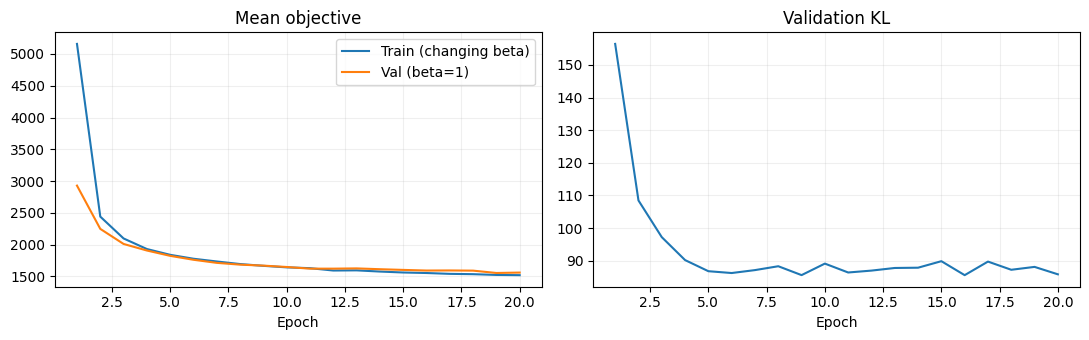

During warm-up, train and validation use different beta values.


In [17]:
fig, ax = plt.subplots(1,2,figsize=(11,3.5))
epochs = [h['epoch'] for h in history]
ax[0].plot(epochs,[h['train'][0] for h in history],label='Train (changing beta)')
ax[0].plot(epochs,[h['val'][0] for h in history],label='Val (beta=1)')
ax[0].set_title('Mean objective'); ax[0].legend()
ax[1].plot(epochs,[h['val'][3] for h in history]); ax[1].set_title('Validation KL')
for a in ax: a.set_xlabel('Epoch'); a.grid(alpha=.2)
plt.tight_layout(); plt.savefig(OUT/'02_learning_curves.png',dpi=160); plt.show()
print('During warm-up, train and validation use different beta values.')


## 8. Generate images

We sample from the standard Gaussian prior and pass the same latent vector to both decoders. We display the predicted image means.


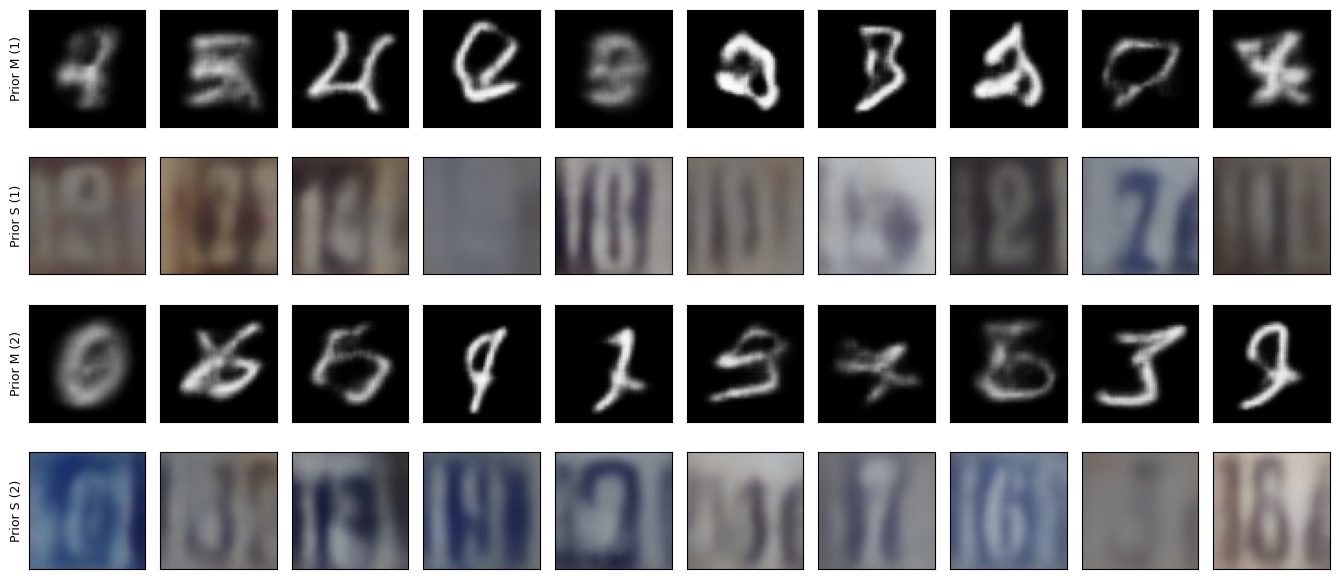

In [18]:
gm, gs = model.sample(20)
show_rows([gm[:10],gs[:10],gm[10:],gs[10:]],
          ['Prior M (1)','Prior S (1)','Prior M (2)','Prior S (2)'],'05_prior_samples.png')


## 9. Reconstructions

We compare test images with joint and single-view reconstructions. We use latent means here to make the comparison deterministic.


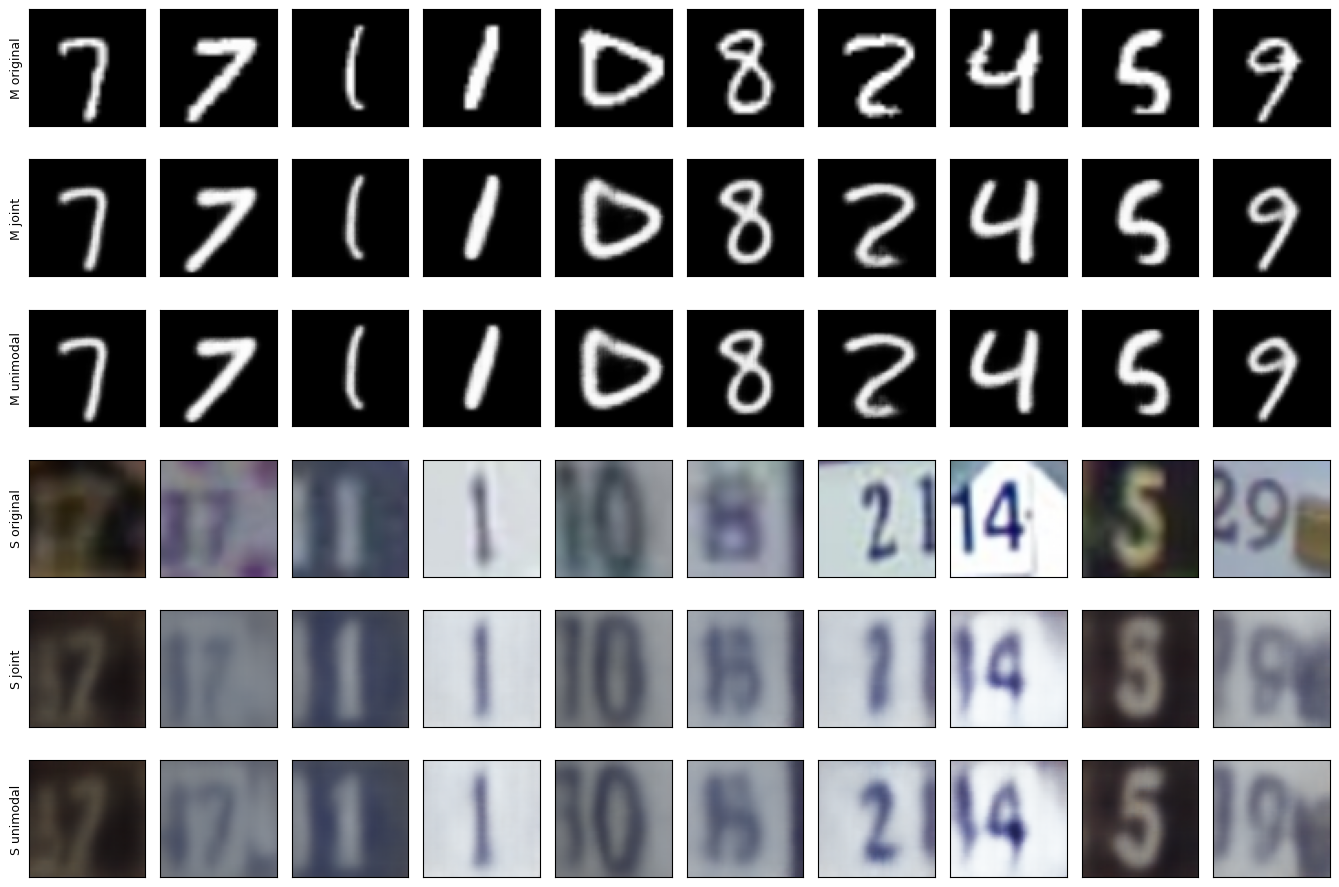

In [19]:
xm, xs, labels = next(iter(test_loader))
xm, xs = xm[:10].to(device), xs[:10].to(device)
with torch.no_grad():
    jm, js, _, _ = model(xm,xs,sample=False)
    mm, ms, _, _ = model(xm,None,sample=False)
    sm, ss, _, _ = model(None,xs,sample=False)
show_rows([xm,jm,mm,xs,js,ss],
          ['M original','M joint','M unimodal','S original','S joint','S unimodal'],
          '03_reconstruction.png')


## 10. Cross-domain generation

For MNIST → SVHN, only MNIST is given to the model. For SVHN → MNIST, only SVHN is given.

We also sample several outputs for one fixed MNIST input.


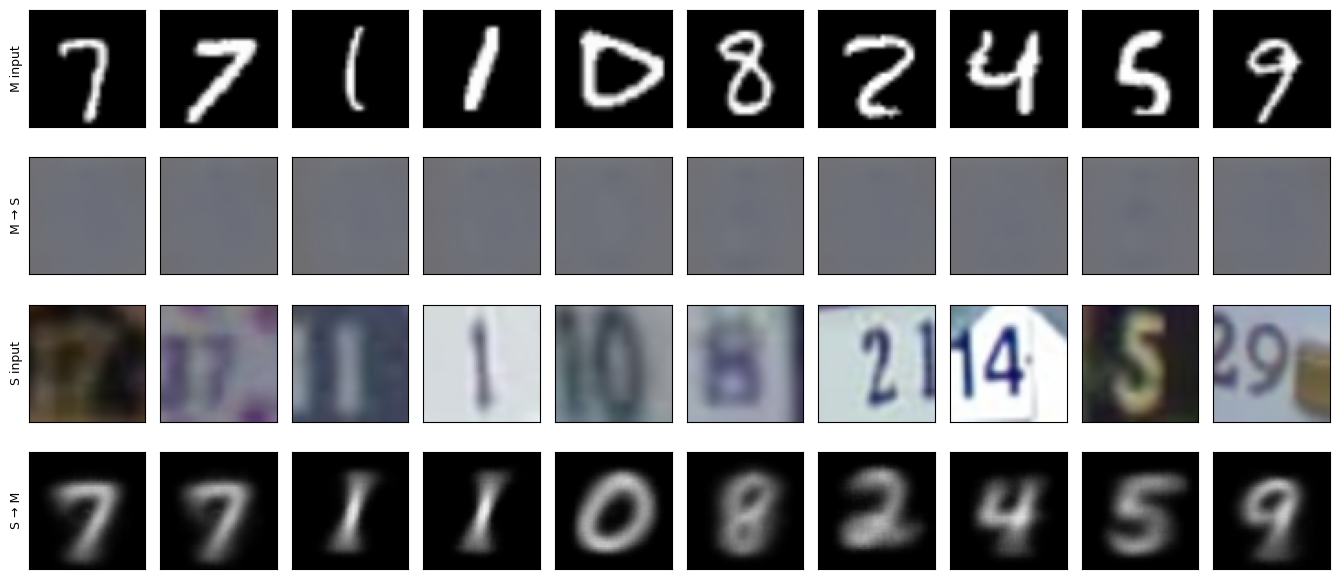

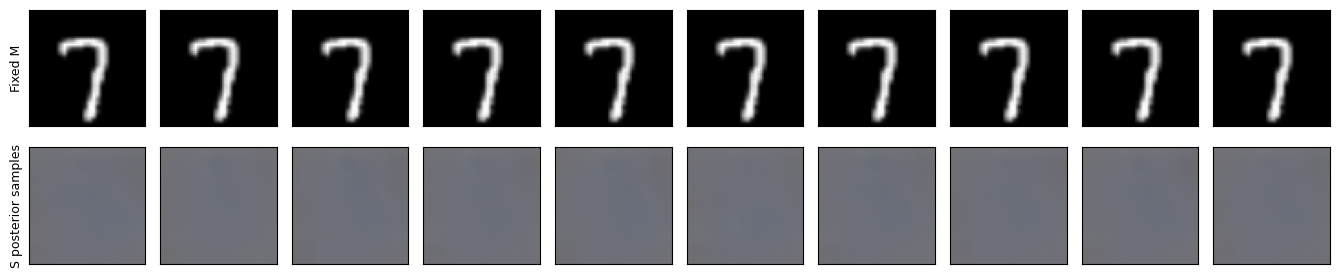

In [20]:
# Generate several SVHN images from one MNIST input.
show_rows([xm,ms,xs,sm],
          ['M input','M → S','S input','S → M'],'04_cross_domain.png')

with torch.no_grad():
    mu, var = model.posterior(xm=xm[:1])
    z = mu + torch.randn(10,LATENT_DIM,device=device)*var.sqrt()
    _, variants = model.decode(z)
show_rows([xm[:1].expand(10,-1,-1,-1),variants],
          ['Fixed M','S posterior samples'],'06_conditional_samples.png')


## 11. Latent interpolation

We interpolate between the joint latent means of two test pairs. Each point is decoded into both domains.


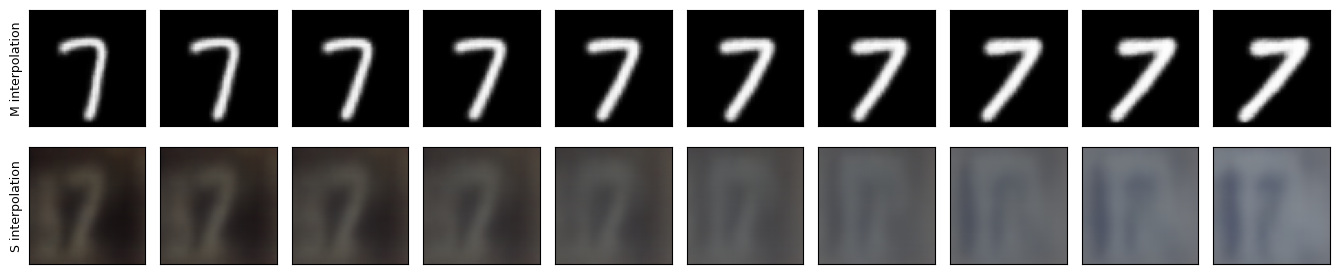

In [21]:
with torch.no_grad():
    mu, _ = model.posterior(xm,xs)
    weights = torch.linspace(0,1,10,device=device).unsqueeze(1)
    z_interp = (1-weights)*mu[0:1] + weights*mu[1:2]
    interp_m, interp_s = model.decode(z_interp)
show_rows([interp_m,interp_s],['M interpolation','S interpolation'],'08_interpolation.png')


## 12. Visualize the latent space with t-SNE

We collect test posterior means for joint, MNIST-only, and SVHN-only inputs. We fit one t-SNE to all three sets so the plots share coordinates. Labels are used only for colouring.

t-SNE shows local structure, but distances between distant groups should not be overinterpreted.


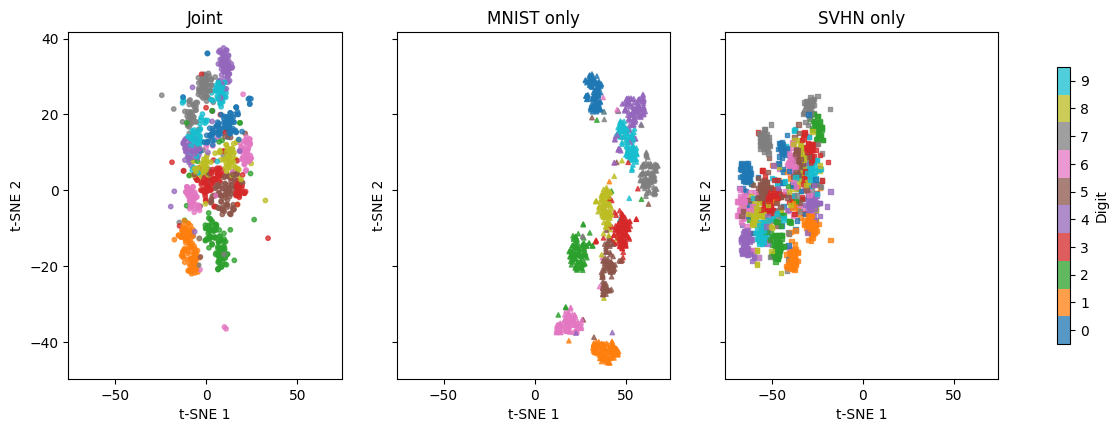

Mean distance between paired single-view latent means: 8.986881


In [22]:
# Fit one t-SNE to all views to share the same coordinates.
@torch.no_grad()
def collect_latents(max_pairs=1000):
    joint, only_m, only_s, ys = [],[],[],[]
    for xm,xs,y in test_loader:
        xm,xs = xm.to(device),xs.to(device)
        joint.append(model.posterior(xm,xs)[0].cpu().numpy())
        only_m.append(model.posterior(xm=xm)[0].cpu().numpy())
        only_s.append(model.posterior(xs=xs)[0].cpu().numpy())
        ys.append(y.numpy())
        if sum(len(a) for a in ys) >= max_pairs: break
    return [np.concatenate(a)[:max_pairs] for a in [joint,only_m,only_s,ys]]

zj,zm,zs,y = collect_latents()
Z = np.concatenate([zj,zm,zs]); n = len(y)
kwargs = dict(n_components=2, perplexity=min(30,len(Z)-1), init='pca',
              learning_rate='auto', random_state=SEED)

kwargs['max_iter' if 'max_iter' in inspect.signature(TSNE).parameters else 'n_iter'] = 1000
embedding = TSNE(**kwargs).fit_transform(Z)
fig, axes = plt.subplots(1,3,figsize=(15,4.5),sharex=True,sharey=True)
for i,(name,marker) in enumerate([('Joint','o'),('MNIST only','^'),('SVHN only','s')]):
    xy = embedding[i*n:(i+1)*n]
    sc = axes[i].scatter(xy[:,0],xy[:,1],c=y,cmap='tab10',vmin=-.5,vmax=9.5,
                         s=10,alpha=.75,marker=marker)
    axes[i].set_title(name); axes[i].set_xlabel('t-SNE 1'); axes[i].set_ylabel('t-SNE 2')
fig.colorbar(sc,ax=axes.tolist(),ticks=range(10),label='Digit',shrink=.8)
fig.savefig(OUT/'07_tsne.png',dpi=180,bbox_inches='tight'); plt.show()
np.savez_compressed(OUT/'latent_test.npz',joint=zj,mnist=zm,svhn=zs,labels=y,tsne=embedding)
print('Mean distance between paired single-view latent means:', np.linalg.norm(zm-zs,axis=1).mean())


### Show images on the t-SNE plot



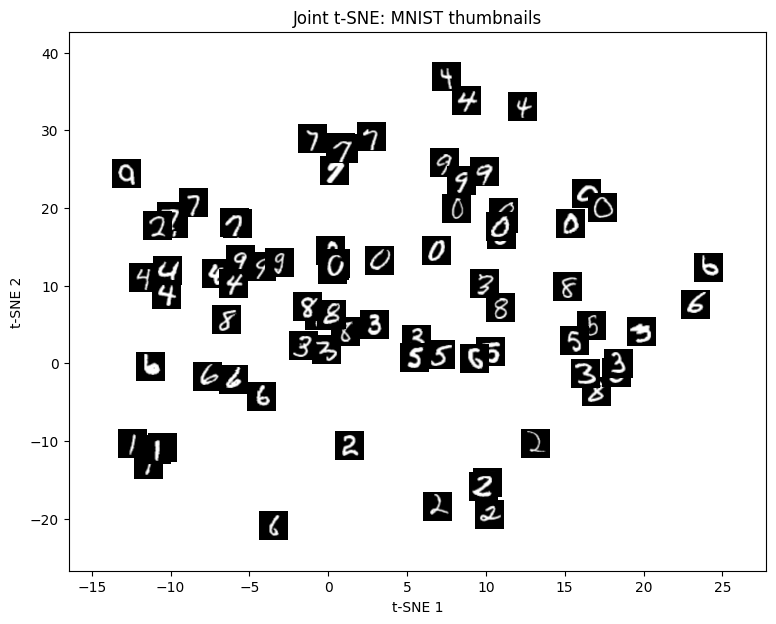

In [23]:
# The test loader keeps the same order as the latent collection.
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

def rescale(img):
    img = (img.detach().cpu()/2 + .5).clamp(0,1)
    return img[0].numpy() if img.shape[0]==1 else img.permute(1,2,0).numpy()

def plot_latent_space_with_images(images,latent):
    fig, ax = plt.subplots(figsize=(9,7))
    for img,point in zip(images,latent):
        image = OffsetImage(rescale(img),zoom=.32,cmap='gray')
        ax.add_artist(AnnotationBbox(image,point,frameon=False))
    low,high = latent.min(0),latent.max(0)
    margin = np.maximum((high-low)*.1,1)
    ax.set_xlim(low[0]-margin[0],high[0]+margin[0])
    ax.set_ylim(low[1]-margin[1],high[1]+margin[1])
    ax.set_title('Joint t-SNE: MNIST thumbnails'); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
    fig.savefig(OUT/'09_tsne_images.png',dpi=160,bbox_inches='tight'); plt.show()

thumbnail_ids = np.linspace(0,n-1,min(80,n),dtype=int)
thumbnail_images = torch.stack([test_ds[int(i)][0] for i in thumbnail_ids])
plot_latent_space_with_images(thumbnail_images,embedding[thumbnail_ids])


## 13. Test metrics

We measure reconstruction and cross-domain MSE per pixel in [0, 1]. Cross-domain MSE compares images with different styles, so it does not directly tell us whether the generated digit is correct.


In [24]:
@torch.no_grad()
def evaluate_mse():
    model.eval()
    scores = {k:0. for k in ['joint_M','joint_S','self_M','self_S','M_to_S','S_to_M']}
    n = 0
    for xm,xs,_ in test_loader:
        xm,xs = xm.to(device),xs.to(device)
        jm,js,_,_ = model(xm,xs,sample=False)
        mm,ms,_,_ = model(xm,None,sample=False)
        sm,ss,_,_ = model(None,xs,sample=False)
        for key,out,target in [('joint_M',jm,xm),('joint_S',js,xs),('self_M',mm,xm),
                               ('self_S',ss,xs),('M_to_S',ms,xs),('S_to_M',sm,xm)]:
            scores[key] += ((out-target)/2).square().flatten(1).mean(1).sum().item()
        n += len(xm)
    return {k:v/n for k,v in scores.items()}
metrics = evaluate_mse()
print(json.dumps(metrics,indent=2))
(OUT/'test_metrics.json').write_text(json.dumps(metrics,indent=2))


{
  "joint_M": 0.004549571119248867,
  "joint_S": 0.004549700096249581,
  "self_M": 0.004454270050674677,
  "self_S": 0.003377517519518733,
  "M_to_S": 0.0498370506465435,
  "S_to_M": 0.04661165223121643
}


205

## 14. Save results

Download the results ZIP and save the executed notebook with its outputs before closing Colab.


In [25]:
import shutil
archive = shutil.make_archive('mvae_results','zip',OUT)
print('Results:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Outside Colab, download the ZIP from the file browser.')


Results: /content/mvae_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References

- Pablo M. Olmos, UC3M: `Lab_VAEs.ipynb` and `STUDENT_Lab_VAEs.ipynb`. Source of the encoder, decoder, Gaussian likelihood, and VAE training structure.

